# 03 - Encoder: fine-tuned XLM-R

| Step | Details |
|---|---|
| Model | `xlm-roberta-base`, fine-tuned on a fixed subsample of the train part |
| Validation | fixed split from `common.split_train_val` (same rows as 02) |
| Long texts | one model, two inference modes: `truncate` (first 512 tokens) vs `chunks` (512-token windows, averaged) |
| Outputs | val / test probabilities in `outputs/`, confusion matrix, `submission_encoder.csv` |

- Kaggle: GPU T4 on, Internet on, competition data attached

## Setup

In [1]:
import subprocess
import sys

REPO = "https://github.com/mohinska/ai_hw3_AIGenTextDetection.git"
REPO_DIR = "/tmp/repo"

subprocess.run(["rm", "-rf", REPO_DIR], check=True)
subprocess.run(["git", "clone", "-q", "--depth", "1", REPO, REPO_DIR], check=True)
sys.path.insert(0, f"{REPO_DIR}/src")

In [2]:
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score
from transformers import (AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding,
                          get_linear_schedule_with_warmup)
from transformers.utils import logging as hf_logging

import common
from common import LABELS, TEXT_COL, LABEL_COL, SEED
from features import chunk_ids, mean_by_text

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
torch.manual_seed(SEED)
np.random.seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = DEVICE == "cuda"
print("device:", DEVICE, torch.cuda.get_device_name(0) if USE_AMP else "")

device: cuda Tesla T4


## Config

In [3]:
MODEL_NAME = "xlm-roberta-base"
FINAL = True            # True: final run - whole train part, only the chunks mode
N_TRAIN = None if FINAL else 40_000   # stratified subsample of the train part
NAME = "encoder_full" if FINAL else "encoder"   # prefix of the saved probabilities / submission
MODES = ["chunks"] if FINAL else ["truncate", "chunks"]
MAX_LEN = 512
STRIDE = 64             # token overlap between neighbouring chunks
MAX_CHUNKS = 8          # chunks per text at inference: ~3.6k tokens, covers ~99% of texts
EPOCHS = 1
BATCH_SIZE = 16
EVAL_BATCH_SIZE = 64
LR = 2e-5
WARMUP = 0.06           # share of steps with linear warmup
LOG_EVERY = 250         # print training loss every N steps

SUBMISSION_PATH = os.path.join(common.WORK_DIR, f"submission_{NAME}.csv")

## Data

In [4]:
train_df, test_df, sample_sub = common.load_data()
trn, val = common.split_train_val(train_df)
trn = common.subsample(trn, N_TRAIN)
y_val = val[LABEL_COL].to_numpy()
L2I = {l: i for i, l in enumerate(LABELS)}
print(f"train part: {len(trn):,} | val: {len(val):,} | test: {len(test_df):,}")

train part: 40,000 | val: 27,236 | test: 25,000


## Training

- Train texts are truncated to the first `MAX_LEN` tokens
- AdamW + linear schedule with warmup, fp16 on GPU, gradient clipping 1.0

In [5]:
tok = AutoTokenizer.from_pretrained(MODEL_NAME)
collate = DataCollatorWithPadding(tok)

# no attention masks here (the collator builds them per batch): saves RAM on the full train
enc = tok(trn[TEXT_COL].fillna("").tolist(), truncation=True, max_length=MAX_LEN, return_attention_mask=False)
train_items = [{"input_ids": ids, "labels": L2I[l]} for ids, l in zip(enc["input_ids"], trn[LABEL_COL])]
del enc
loader = DataLoader(train_items, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate,
                    generator=torch.Generator().manual_seed(SEED))
print(f"{len(loader):,} steps per epoch")

2,500 steps per epoch


In [6]:
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=len(LABELS)).to(DEVICE)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
total_steps = EPOCHS * len(loader)
sched = get_linear_schedule_with_warmup(opt, int(WARMUP * total_steps), total_steps)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

model.train()
step, losses, t0 = 0, [], time.time()
for epoch in range(EPOCHS):
    for batch in loader:
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
            loss = model(**batch).loss
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt)
        scaler.update()
        sched.step()
        losses.append(loss.item())
        step += 1
        if step % LOG_EVERY == 0 or step == total_steps:
            print(f"step {step}/{total_steps} | loss {np.mean(losses[-LOG_EVERY:]):.4f} | "
                  f"{(time.time() - t0) / 60:.1f} min")

step 250/2500 | loss 0.8055 | 2.0 min
step 500/2500 | loss 0.4786 | 4.0 min
step 750/2500 | loss 0.3905 | 6.2 min
step 1000/2500 | loss 0.3690 | 8.3 min
step 1250/2500 | loss 0.3535 | 10.4 min
step 1500/2500 | loss 0.3446 | 12.5 min
step 1750/2500 | loss 0.3059 | 14.6 min
step 2000/2500 | loss 0.3149 | 16.7 min
step 2250/2500 | loss 0.3149 | 18.8 min
step 2500/2500 | loss 0.2982 | 21.0 min


## Inference: truncate vs chunks

| Mode | What the model sees |
|---|---|
| `truncate` | first 512 tokens |
| `chunks` | up to `MAX_CHUNKS` windows of 512 tokens with `STRIDE` overlap; class probabilities averaged per text |

In [7]:
@torch.no_grad()
def predict(ids_list):
    """Class probabilities for tokenized sequences (sorted by length for fast padding)."""
    model.eval()
    order = np.argsort([len(x) for x in ids_list])
    probs = np.zeros((len(ids_list), len(LABELS)), dtype=np.float32)
    for s in range(0, len(order), EVAL_BATCH_SIZE):
        idx = order[s:s + EVAL_BATCH_SIZE]
        batch = collate([{"input_ids": ids_list[i]} for i in idx])
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
            logits = model(**batch).logits
        probs[idx] = torch.softmax(logits.float(), dim=-1).cpu().numpy()
    return probs


def predict_texts(texts, mode):
    texts = texts.fillna("").tolist()
    if mode == "truncate":
        return predict(tok(texts, truncation=True, max_length=MAX_LEN)["input_ids"])
    ids, text_idx = chunk_ids(texts, tok, MAX_LEN, STRIDE, MAX_CHUNKS)
    return mean_by_text(predict(ids), text_idx, len(texts))


def to_labels(proba):
    return np.array(LABELS)[proba.argmax(1)]


def scores(name, proba):
    pred = to_labels(proba)
    per_class = f1_score(y_val, pred, labels=LABELS, average=None)
    return {"model": name, "macro_f1": f1_score(y_val, pred, average="macro"),
            **{f"f1_{l}": f for l, f in zip(LABELS, per_class)}}

In [8]:
val_proba = {}
for mode in MODES:
    t0 = time.time()
    val_proba[mode] = predict_texts(val[TEXT_COL], mode)
    common.save_proba(val["id"], val_proba[mode], LABELS, f"{NAME}_{mode}", "val")
    print(f"{mode}: {(time.time() - t0) / 60:.1f} min")

truncate: 3.4 min
chunks: 6.5 min


## Results on the validation split

- Baseline row appears if the output of 02 is attached as Kaggle input

In [9]:
rows = [scores(f"{NAME}_{m}", p) for m, p in val_proba.items()]
for path in common.find_outputs("val_proba_baseline.csv")[:1]:
    rows.append(scores("baseline_tfidf (02)", common.load_proba(path, val["id"])))
results = pd.DataFrame(rows).sort_values("macro_f1", ascending=False).round(4).reset_index(drop=True)
results.to_csv(os.path.join(common.WORK_DIR, "outputs", "encoder_results.csv"), index=False)
results

,model,macro_f1,f1_human,f1_ai,f1_fusion
0,baseline_tfidf (02),0.8724,0.8092,0.9843,0.8238
1,encoder_chunks,0.8530,0.7649,0.9800,0.8140
2,encoder_truncate,0.8353,0.7489,0.9848,0.7721


In [10]:
BEST_MODE = max(val_proba, key=lambda m: f1_score(y_val, to_labels(val_proba[m]), average="macro"))
val_pred = to_labels(val_proba[BEST_MODE])
print("best mode:", BEST_MODE, "\n")
print(classification_report(y_val, val_pred, labels=LABELS, digits=4))

best mode: chunks 

              precision    recall  f1-score   support

       human     0.8282    0.7106    0.7649      6673
          ai     0.9654    0.9951    0.9800     12195
      fusion     0.7879    0.8418    0.8140      8368

    accuracy                         0.8783     27236
   macro avg     0.8605    0.8492    0.8530     27236
weighted avg     0.8772    0.8783    0.8763     27236



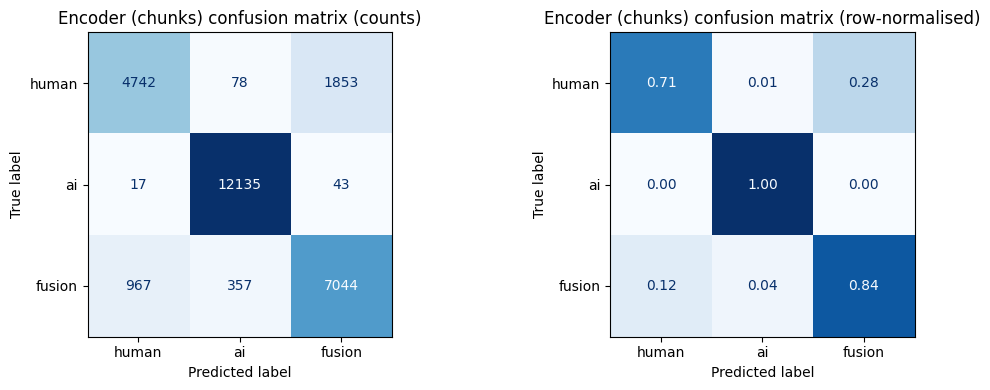

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, norm, title in zip(axes, [None, "true"], ["counts", "row-normalised"]):
    ConfusionMatrixDisplay.from_predictions(y_val, val_pred, labels=LABELS, normalize=norm,
                                            values_format=".2f" if norm else "d",
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"Encoder ({BEST_MODE}) confusion matrix ({title})")
common.save_fig("encoder_cm.png")

In [12]:
# macro-F1 per domain for both modes: where chunking helps
pd.concat({m: common.f1_by(y_val, to_labels(p), val["domain"])["macro_f1"] for m, p in val_proba.items()},
          axis=1).assign(n=val["domain"].value_counts()).sort_values("n", ascending=False)

,truncate,chunks,n
g,,,
student_essays,0.8991,0.9107,5433
bundestag,0.8144,0.8468,5229
cnn_news,0.8683,0.8862,4360
blog_authorship_corpus,0.7792,0.7770,4022
house_of_commons,0.8149,0.8429,3229
euro_court_cases,0.7988,0.8423,2757
arxiv_papers,0.5807,0.4669,1428
gutenberg,0.6942,0.7842,778


## Test predictions and submission

In [13]:
test_proba = predict_texts(test_df[TEXT_COL], BEST_MODE)
common.save_proba(test_df["id"], test_proba, LABELS, f"{NAME}_{BEST_MODE}", "test")
submission = common.save_submission(test_df["id"], to_labels(test_proba), sample_sub, SUBMISSION_PATH)
print("saved", SUBMISSION_PATH, submission.shape)
submission["label"].value_counts(normalize=True).round(3)

saved /kaggle/working/submission_encoder.csv (25000, 2)


label
ai        0.525
fusion    0.263
human     0.212
Name: proportion, dtype: float64

## Conclusions

- **Chunks vs truncate:** `chunks` 0.8530 vs `truncate` 0.8353 (+0.018) -> reading the whole text helps; biggest gains on long-text domains: `gutenberg` +0.090, `euro_court_cases` +0.044, `bundestag` +0.032
- **Encoder vs baseline:** 0.8530 vs 0.8724 -> 40k texts, 1 epoch is not enough to beat TF-IDF; loss still falling at the end (0.30) -> more data / epochs should help
- **LB:** 0.84822 vs val 0.8530
- **`arxiv_papers` collapses:** 0.47 (`chunks`) vs 0.85 for the baseline -> the encoder does not see text length, which separates `ai` there (hypothesis)
- **Different errors than the baseline:** `human` recall 0.71 (often predicted as `fusion`), baseline has the opposite bias (`fusion` recall 0.79) -> good candidate for the ensemble in `05`
- **Encoder wins** on `student_essays` (0.911 vs 0.896) and `blog_authorship_corpus` (0.777 vs 0.752)